**Principal Component Analysis**

In [22]:
#Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

In [23]:
#Load dataset
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/ML/stock_market.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Shape: (100, 6)


,Stock_ID,Company,Date,Open_Price,Close_Price,Volume
0,1,"Lopez, Merritt and Elliott",2024-01-01,1186.56,164.23,151642
1,2,"Rivera, Riley and Ford",2024-01-02,970.51,1086.51,756035
2,3,Terry and Sons,2024-01-03,411.11,1099.07,311930
3,4,"Smith, Moore and Lindsey",2024-01-04,1149.21,83.63,815573
4,5,Tate Inc,2024-01-05,503.96,228.26,884494


In [24]:
#Data preprocessing
df['Date'] = pd.to_datetime(df['Date'])

df = df.sort_values('Date').reset_index(drop=True)

df['Date_Number'] = (
    df['Date'] - df['Date'].min()
).dt.days

df['Price_Direction'] = (
    df['Close_Price'].shift(-1) > df['Close_Price']
).astype(int)

df = df.iloc[:-1].copy()

features = [
    'Stock_ID',
    'Date_Number',
    'Open_Price',
    'Close_Price',
    'Volume'
]

X = df[features]
y = df['Price_Direction']

print("Features:", features)
print("Number of features:", X.shape[1])
print("Target classes:")
print(y.value_counts())


Features: ['Stock_ID', 'Date_Number', 'Open_Price', 'Close_Price', 'Volume']
Number of features: 5
Target classes:
Price_Direction
0    50
1    49
Name: count, dtype: int64


In [25]:

#Apply StandardScaler
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_imputed = imputer.fit_transform(X)
X_scaled = scaler.fit_transform(X_imputed)

print("Feature scaling completed!")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed!
Scaled data shape: (99, 5)


Explained variance ratio:
[0.41293782 0.22834029 0.18843942 0.17028247 0.        ]

Cumulative explained variance:
[0.41293782 0.64127811 0.82971753 1.         1.        ]


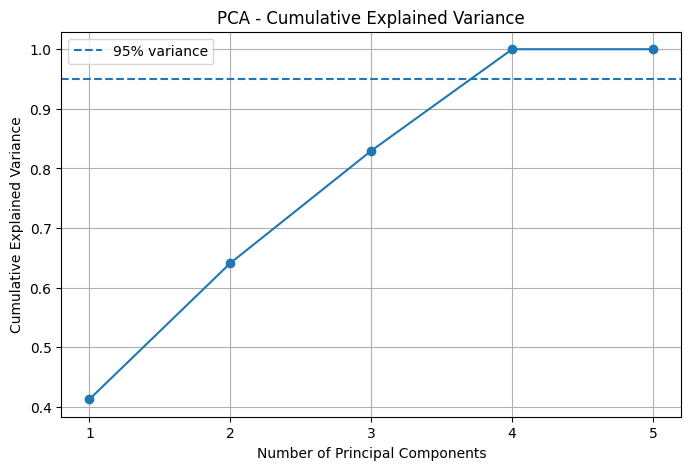

In [26]:
#Apply PCA and plot explained variance
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained variance ratio:")
print(explained_variance)

print("\nCumulative explained variance:")
print(cumulative_variance)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)
plt.axhline(y=0.95, linestyle='--', label='95% variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)
plt.legend()
plt.show()

In [27]:
#Retain the top principal components
pca_95 = PCA(n_components=0.95)

X_pca_95 = pca_95.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Reduced number of components:", X_pca_95.shape[1])
print(
    "Variance retained:",
    round(np.sum(pca_95.explained_variance_ratio_), 4) * 100,
    "%"
)
print("Reduced data shape:", X_pca_95.shape)

Original number of features: 5
Reduced number of components: 4
Variance retained: 100.0 %
Reduced data shape: (99, 4)


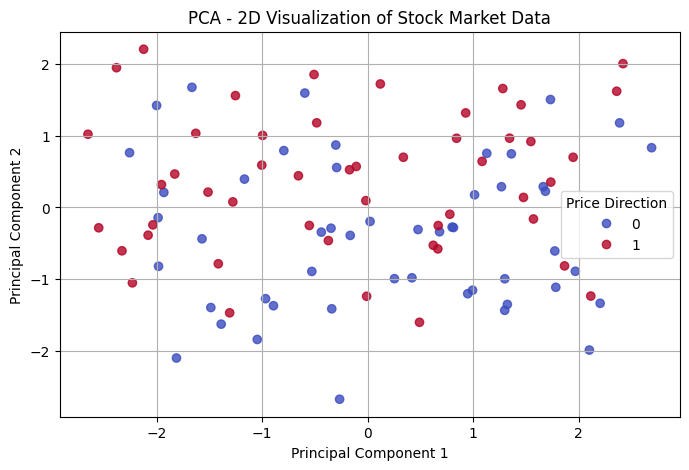

Variance explained by 2 components: 64.13 %


In [28]:
#Visualize the data in 2D
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=y.to_numpy(),
    cmap='coolwarm',
    alpha=0.8
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - 2D Visualization of Stock Market Data')
plt.legend(
    *scatter.legend_elements(),
    title='Price Direction'
)
plt.grid(True)
plt.show()

print(
    "Variance explained by 2 components:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [29]:
#Compare classification accuracy before and after PCA
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

original_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

pca_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95)),
    ('classifier', LogisticRegression(max_iter=1000))
])

original_model.fit(X_train, y_train)
pca_model.fit(X_train, y_train)

original_predictions = original_model.predict(X_test)
pca_predictions = pca_model.predict(X_test)

original_accuracy = accuracy_score(
    y_test, original_predictions
)

pca_accuracy = accuracy_score(
    y_test, pca_predictions
)

print("Original Features Accuracy:",
      round(original_accuracy * 100, 2), "%")

print("PCA Reduced Features Accuracy:",
      round(pca_accuracy * 100, 2), "%")

print("Original Number of Features:", X.shape[1])
print("PCA Components Used:",
      pca_model.named_steps['pca'].n_components_)

Original Features Accuracy: 75.0 %
PCA Reduced Features Accuracy: 75.0 %
Original Number of Features: 5
PCA Components Used: 4


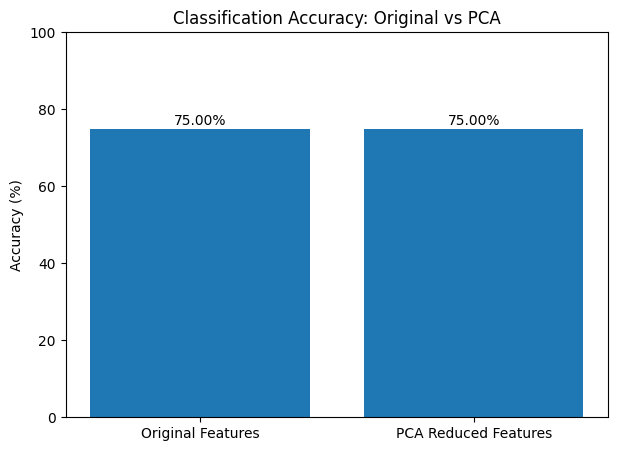

In [30]:
#Plot accuracy comparison
models = ['Original Features', 'PCA Reduced Features']
accuracies = [
    original_accuracy * 100,
    pca_accuracy * 100
]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.ylabel('Accuracy (%)')
plt.title('Classification Accuracy: Original vs PCA')
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{accuracy:.2f}%',
        ha='center'
    )

plt.show()